# Multivariable calculus 5: Multiple integrals and the bell curve

*Learning path: multivariable calculus, part 5 of 7.* [Index](README.md) · Previous: [Lagrange multipliers](04-lagrange-multipliers.ipynb) · Next: [Vector fields and line integrals](06-vector-fields-and-line-integrals.ipynb)

The bell curve $e^{-x^2}$ is everywhere in science: measurement errors, heights of people, heat spreading in a rod.
Its total area, $\int_{-\infty}^{\infty} e^{-x^2}\,dx$, is $\sqrt\pi$. Yet $e^{-x^2}$ has no antiderivative you can
write with the functions you know. How can anyone know the area? The answer is one of the great tricks of
mathematics: go up a dimension, to a **double integral**, and switch to polar coordinates. This lesson builds the
tools and then does the trick.

**Who this is for.** You can integrate functions of one variable, including by substitution
([foundations 7](../foundations/08-calculus.ipynb)), and you know polar coordinates and the Jacobian matrix's idea
from [lesson 2](02-partial-derivatives-and-gradient.ipynb).

**What you will be able to do afterwards:**

1. compute double and triple integrals as iterated integrals, over rectangles and over regions bounded by curves;
2. change the order of integration;
3. change to polar coordinates, and explain the extra factor $r$ with the Jacobian;
4. compute $\int e^{-x^2}dx = \sqrt\pi$, and use the error function and the gamma function that grow out of it.

Plan a bit over an hour.

## 1. Volume under a surface

The double integral $\iint_R f(x, y)\,dA$ over a region $R$ is the volume between the graph of $f \ge 0$ and the
region: cut $R$ into small rectangles, multiply each area by the height there, add, and refine. **Fubini's theorem**
says that over a rectangle you can do it one variable at a time: first integrate in $y$ with $x$ fixed (the area of
a slice), then integrate those slice areas in $x$.

Volume under $f = x^2 + y^2$ over the square $0 \le x, y \le 1$. By hand: the inner integral is
$\int_0^1 (x^2 + y^2)\,dy = x^2 + \tfrac13$, and $\int_0^1 (x^2 + \tfrac13)\,dx = \tfrac23$.

In [1]:
int(x^2 + y^2, y, 0, 1)
int(int(x^2 + y^2, y, 0, 1), x, 0, 1)

x^2+1/3

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

2/3

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The inner `int` gives a function of $x$ (the slice area), the outer one integrates it: an **iterated integral**.

**Try this.** Do it in the other order, $x$ first. Same answer? Then compute $\int_0^2\int_0^1 xy\,dy\,dx$ by hand
and check.

## 2. Regions bounded by curves

The region between the parabola $y = x^2$ and the line $y = x$ for $0 \le x \le 1$:

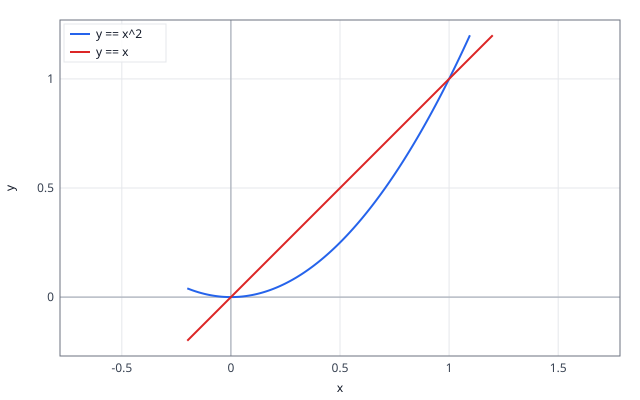

> `implicitplot`: Draws the curve F(x, y) = 0, or an equation such as x^2 + y^2 == 1, in the window x0..x1, y0..y1 (equal scales).

In [2]:
implicitplot([y == x^2, y == x], x, -0.2, 1.2, y, -0.2, 1.2)

For each $x$, $y$ runs from the parabola up to the line. So the inner limits depend on $x$:

$$\text{Area} = \int_0^1 \int_{x^2}^{x} 1 \,dy\,dx = \int_0^1 (x - x^2)\,dx = \tfrac16.$$

In [3]:
int(int(1, y, x^2, x), x, 0, 1)

1/6

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

**Changing the order.** Read the same region the other way: for each $y$ between $0$ and $1$, $x$ runs from the
line $x = y$ to the parabola $x = \sqrt y$. Then $\int_0^1\int_y^{\sqrt y} 1\,dx\,dy$ must give the same $\tfrac16$.
Sometimes one order is easy and the other impossible; the exercises have one.

In [4]:
int(int(1, x, y, sqrt(y)), y, 0, 1)

1/6

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

**Try this.** Compute $\iint_R xy\,dA$ over the same region in both orders.

## 3. Polar coordinates and the factor r

For round regions use polar coordinates, $x = r\cos\theta$, $y = r\sin\theta$. A small rectangle in the
$(r, \theta)$ plane, of size $dr \times d\theta$, becomes a small curved box in the plane of size $dr$ by
$r\,d\theta$: its area is $r\,dr\,d\theta$, not $dr\,d\theta$. The factor is the determinant of the Jacobian matrix
of the change of variables:

In [5]:
J = jacobian([r*cos(theta), r*sin(theta)], [r theta])
simplify(det(J))

[cos(theta), -r*sin(theta);
 sin(theta),  r*cos(theta)]

> Row i of the Jacobian holds the partial derivatives of the i-th function. It is the best linear approximation of the map near a point; for a change of variables its determinant is the local area (or volume) scale factor, as in dx dy = |det J| dr dθ.

r

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

So $dA = r\,dr\,d\theta$. The area of a disk of radius $a$: $\int_0^{2\pi}\int_0^a r\,dr\,d\theta = \pi a^2$.

In [6]:
int(int(r, r, 0, a), theta, 0, 2*pi)

pi*a^2

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

**Try this.** The volume of the dome $z = 9 - x^2 - y^2$ above the disk $x^2 + y^2 \le 9$ (lesson 1). In polar
coordinates the height is $9 - r^2$. Compute by hand, then check.

## 4. The bell curve trick

Now the area under $e^{-x^2}$. Call it $I = \int_{-\infty}^{\infty} e^{-x^2}\,dx$. Then

$$I^2 = \int_{-\infty}^{\infty} e^{-x^2}dx \int_{-\infty}^{\infty} e^{-y^2}dy = \iint_{\mathbb R^2} e^{-(x^2 + y^2)}\,dA.$$

The whole plane is a disk of infinite radius, and $x^2 + y^2 = r^2$:

$$I^2 = \int_0^{2\pi}\int_0^\infty e^{-r^2}\, r\,dr\,d\theta.$$

The factor $r$ is a gift: $r e^{-r^2}$ **does** have an antiderivative, $-\tfrac12 e^{-r^2}$. So the inner integral is
$\tfrac12$, and $I^2 = 2\pi \cdot \tfrac12 = \pi$. By hand, done. Galileo agrees:

In [7]:
int(int(exp(-r^2)*r, r, 0, inf), theta, 0, 2*pi)

pi

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

$I^2 = \pi$, so $I = \sqrt\pi$. Galileo also knows the one-dimensional answer directly:

In [8]:
int(exp(-x^2), x, -inf, inf)

sqrt(pi)

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

**Try this.** Use the substitution $x = t/\sqrt 2$ by hand to find $\int_{-\infty}^{\infty} e^{-t^2/2}\,dt$. Check it.
This is why the normal distribution has the factor $1/\sqrt{2\pi}$ in front.

## 5. A new function: erf

Areas under the bell curve over a finite interval come up constantly, and they have no elementary formula. So
mathematicians gave them a name, the **error function**:

$$\operatorname{erf}(x) = \frac{2}{\sqrt\pi}\int_0^x e^{-t^2}\,dt.$$

The factor makes $\operatorname{erf}(\infty) = 1$. It is a function like $\sin$ or $\log$: it has a graph,
derivatives and values. Galileo uses it for antiderivatives:

sqrt(pi)*erf(x)/2

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

2*exp(-x^2)/sqrt(pi)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

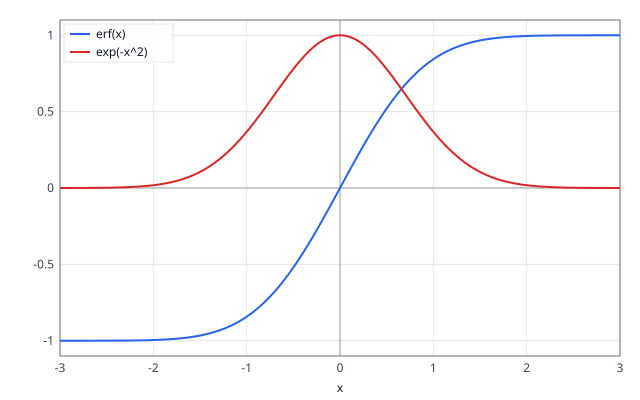

> `plot`: Plots one or more expressions of x.

In [9]:
int(exp(-x^2), x)
diff(erf(x), x)
plot(erf(x), exp(-x^2), x, -3, 3)

How to read the plot: blue is $\operatorname{erf}(x)$, rising from $-1$ to $1$, steepest at $0$ where the bell (red)
is highest; the bell is its derivative up to the factor $2/\sqrt\pi$.

**The normal distribution.** A quantity that is normally distributed with mean 0 and standard deviation 1 has
density $e^{-t^2/2}/\sqrt{2\pi}$. The probability of landing within one standard deviation:

In [10]:
p1 = int(exp(-t^2/2)/sqrt(2*pi), t, -1, 1)
eval(p1)

erf(sqrt(2)/2)

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0.6826894921370859

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

About 68%: the "68–95–99.7 rule" of statistics.

**Try this.** Find the probabilities within 2 and within 3 standard deviations. Do you get 95% and 99.7%?

## 6. Another new function: gamma

Integrals like $\int_0^\infty t^{n} e^{-t}\,dt$ give factorials: by parts, $\int_0^\infty t^n e^{-t}dt = n!$.

In [11]:
int(t^4*exp(-t), t, 0, inf)

24

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The integral makes sense for any power $t^{x-1}$ with $x > 0$, not only whole numbers. That defines the **gamma
function**,

$$\Gamma(x) = \int_0^\infty t^{x-1}e^{-t}\,dt, \qquad \Gamma(n) = (n-1)!,$$

which fills in the factorials between the whole numbers. And here the bell curve returns: with $t = u^2$,
$\Gamma(\tfrac12) = \int_0^\infty t^{-1/2}e^{-t}dt = 2\int_0^\infty e^{-u^2}du = \sqrt\pi$.

sqrt(pi)

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

sqrt(pi)

> `gamma`: The gamma function, the integral of t^(x-1) e^(-t) from 0 to inf: gamma(n) = (n-1)!, gamma(1/2) = sqrt(pi), exact at whole and half-whole numbers.

24

> `gamma`: The gamma function, the integral of t^(x-1) e^(-t) from 0 to inf: gamma(n) = (n-1)!, gamma(1/2) = sqrt(pi), exact at whole and half-whole numbers.

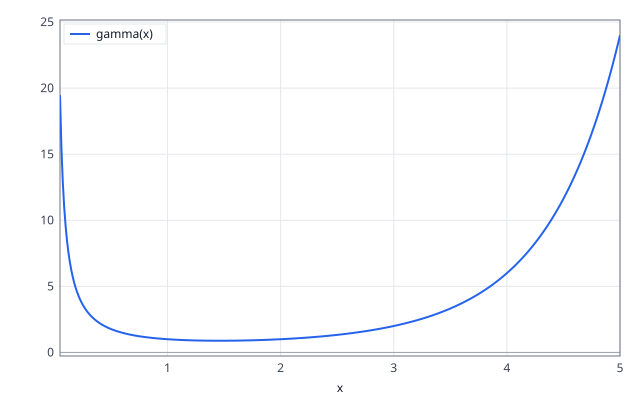

> `plot`: Plots one or more expressions of x.

In [12]:
int(t^(-1/2)*exp(-t), t, 0, inf)
gamma(1/2)
gamma(5)
plot(gamma(x), x, 0.05, 5)

**Try this.** Use $\Gamma(x + 1) = x\,\Gamma(x)$ (integrate by parts to prove it, if you like) and $\Gamma(\tfrac12) = \sqrt\pi$
to find $\Gamma(\tfrac52)$ by hand. Check with `gamma(5/2)`.

## 7. Triple integrals, briefly

One more dimension works the same way. The volume of the tetrahedron $x, y, z \ge 0$, $x + y + z \le 1$, from the
inside out:

In [13]:
int(int(int(1, z, 0, 1 - x - y), y, 0, 1 - x), x, 0, 1)

1/6

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

In spherical coordinates the volume element is $r^2 \sin\theta\,dr\,d\theta\,d\varphi$, again the determinant of a
Jacobian. The volume of a ball of radius $a$:

In [14]:
int(int(int(r^2*sin(theta), r, 0, a), theta, 0, pi), phi, 0, 2*pi)

4*pi*a^3/3

> `int` (see `integrate`): Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

## Exercises

1. **Swap the order.** $\int_0^1\int_x^1 e^{y^2}\,dy\,dx$ can't be done in this order (why?). Draw the region, swap
   the order, and compute it by hand. Check with Galileo.
2. **A cone.** Find the volume inside the cone $z = \sqrt{x^2 + y^2}$ and below the plane $z = 2$, with polar
   coordinates.
3. **Bell curve moments.** Compute $\int_{-\infty}^{\infty} x^2 e^{-x^2/2}\,dx / \sqrt{2\pi}$ (the variance of the
   standard normal distribution).
4. **Area of an ellipse.** Use $x = a r\cos\theta$, $y = b r\sin\theta$. Compute the Jacobian determinant and the
   area of $x^2/a^2 + y^2/b^2 \le 1$.
5. **Volume of a 4D ball.** The volume of the unit ball in $n$ dimensions is $\pi^{n/2}/\Gamma(n/2 + 1)$. Check it
   for $n = 2$ and $n = 3$, then find it for $n = 4$ and $n = 5$. In which dimension is the unit ball biggest? (Plot
   the formula with `plot` for $1 \le n \le 15$.)

## Hints and answers

* **Section 1, Try this.** Same answer, $\tfrac23$. And $\int_0^2\int_0^1 xy\,dy\,dx = \int_0^2 \tfrac{x}{2}\,dx = 1$.
* **Section 2, Try this.** $\int_0^1\int_{x^2}^{x} xy\,dy\,dx = \int_0^1 \tfrac x2(x^2 - x^4)\,dx = \tfrac1{24}$.
* **Section 3, Try this.** $\int_0^{2\pi}\int_0^3 (9 - r^2)\,r\,dr\,d\theta = 2\pi\left(\tfrac{81}{2} - \tfrac{81}{4}\right) = \tfrac{81\pi}{2}$.
* **Section 4, Try this.** $\int e^{-t^2/2}dt = \sqrt 2\int e^{-x^2}dx = \sqrt{2\pi}$.
* **Section 5, Try this.** $\operatorname{erf}(\sqrt 2) \approx 0.9545$ and $\operatorname{erf}(3/\sqrt 2) \approx 0.9973$. Yes.
* **Section 6, Try this.** $\Gamma(\tfrac52) = \tfrac32 \cdot \tfrac12 \cdot \sqrt\pi = \tfrac34\sqrt\pi$.
* **Exercise 1.** $e^{y^2}$ has no elementary antiderivative in $y$. The region is the triangle $0 \le x \le y \le 1$;
  in the other order $\int_0^1\int_0^y e^{y^2}dx\,dy = \int_0^1 y e^{y^2}dy = \tfrac{e - 1}{2}$.
* **Exercise 2.** $\int_0^{2\pi}\int_0^2 (2 - r)\,r\,dr\,d\theta = \tfrac{8\pi}{3}$.
* **Exercise 3.** 1.
* **Exercise 4.** The determinant is $abr$; the area is $\pi ab$.
* **Exercise 5.** $\pi$ and $\tfrac43\pi$; $n = 4$: $\tfrac{\pi^2}{2} \approx 4.93$; $n = 5$: $\tfrac{8\pi^2}{15} \approx 5.26$,
  the largest. After that the volume shrinks toward 0: in high dimensions almost all of the cube
  $[-1, 1]^n$ lies in its corners, outside the ball.

## Sources

1. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), chapter 15.
2. G. Strang and E. Herman, *Calculus Volume 3*, OpenStax (2016), chapter 5.
3. P. J. Davis, "Leonhard Euler's integral: a historical profile of the gamma function", *American Mathematical
   Monthly* 66 (1959) 849–869.
4. NIST *Digital Library of Mathematical Functions*, chapters 5 (gamma) and 7 (error functions), dlmf.nist.gov.